In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import torch
import torchinfo
from torch.utils.data import DataLoader
from torchlake.common.constants import IMAGENET_MEAN, IMAGENET_STD
from torchlake.common.controller.trainer import ClassificationTrainer
from torchlake.common.controller.evaluator import ClassificationEvaluator
from torchlake.common.utils.platform import get_num_workers, get_file_size
from torchlake.image_classification.models.mobilenetv4 import MobileNetV4
from torchvision import transforms
from torchvision.datasets import GTSRB

# Setting

In [2]:
IMAGE_SIZE = 224
BATCH_SIZE = 64

In [3]:
artifact_path = Path("../../artifacts/mobilenet")
artifact_path.mkdir(exist_ok=True)

data_path = Path("../../data/gtsrb")

In [4]:
DEVICE = torch.device("cuda:0")

# data

In [5]:
preprocess = transforms.Compose(
    [
        transforms.ColorJitter(brightness=0.2, saturation=0.2, contrast=0.2),
        transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
        transforms.ToTensor(),
        transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
    ]
)

In [6]:
train_dataset = GTSRB(
    data_path.as_posix(),
    split="train",
    transform=preprocess,
    download=True,
)

In [7]:
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    drop_last=True,
    pin_memory=True,
    num_workers=get_num_workers(),
)

In [8]:
num_class = 43

In [9]:
len(train_dataset)

26640

0


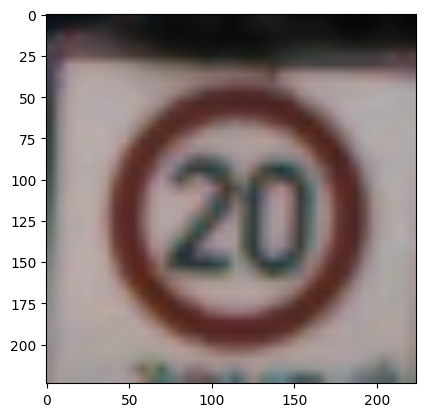

In [10]:
import random
from torchlake.common.utils.convert import img_tensor_to_np

demo_img, demo_label = random.choice(train_dataset)
print(demo_label)
plt.imshow((img_tensor_to_np(demo_img) * IMAGENET_STD + IMAGENET_MEAN).clip(0, 1))

# model

In [11]:
model = MobileNetV4(output_size=num_class, key="conv_medium").to(DEVICE)

In [12]:
torchinfo.summary(model)

Layer (type:depth-idx)                                  Param #
MobileNetV4                                             --
├─Conv2dNormActivation: 1-1                             --
│    └─Conv2d: 2-1                                      864
│    └─BatchNorm2d: 2-2                                 64
│    └─ReLU: 2-3                                        --
├─Sequential: 1-2                                       --
│    └─FusedInvertedBottleneck: 2-4                     --
│    │    └─Sequential: 3-1                             43,360
│    └─UniversalInvertedBottleneck: 2-5                 --
│    │    └─Sequential: 3-2                             30,832
│    └─ResBlock: 2-6                                    --
│    │    └─UniversalInvertedBottleneck: 3-3            28,720
│    │    └─Identity: 3-4                               --
│    └─UniversalInvertedBottleneck: 2-7                 --
│    │    └─Sequential: 3-5                             130,320
│    └─ResBlock: 2-8             

# training

In [13]:
epochs = 10
acc_iters = 64 // BATCH_SIZE

In [14]:
trainer = ClassificationTrainer(epochs, DEVICE, acc_iters)
trainer.recorder.increment_dataset_size(len(train_dataset))

In [15]:
criterion = trainer.get_criterion(num_class)
optim = torch.optim.Adam(model.parameters())

In [16]:
training_loss = trainer.run(train_loader, model, optim, criterion)

Enable AMP: False
Training...


100%|██████████| 416/416 [06:39<00:00,  1.04it/s]


------------------------------------
Epoch 1
------------------------------------
total: 1.8971e-02 (0.00%)


100%|██████████| 416/416 [02:18<00:00,  3.01it/s]


------------------------------------
Epoch 2
------------------------------------
total: 1.6160e-03 (-91.00%)


100%|██████████| 416/416 [02:16<00:00,  3.04it/s]


... (11 outputs left out)

100%|██████████| 416/416 [01:28<00:00,  4.72it/s]


------------------------------------
Epoch 9
------------------------------------
total: 4.4437e-04 (49.00%)


100%|██████████| 416/416 [01:28<00:00,  4.68it/s]

------------------------------------
Epoch 10
------------------------------------
total: 2.7162e-04 (-39.00%)


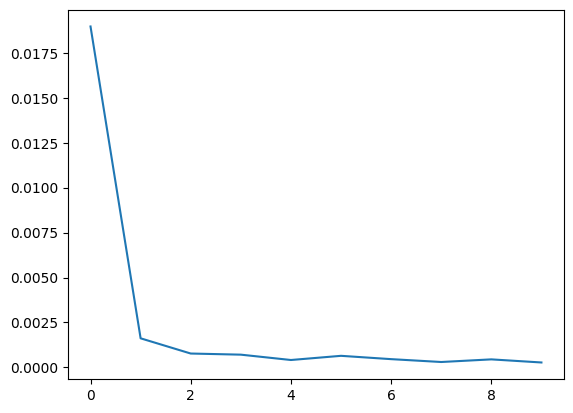

In [17]:
plt.plot(training_loss)

# inference

In [18]:
test_preprocess = transforms.Compose(
    [
        transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
        transforms.ToTensor(),
        transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
    ]
)

In [19]:
test_dataset = GTSRB(
    data_path.as_posix(),
    split="test",
    transform=test_preprocess,
    download=True,
)

In [20]:
test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    pin_memory=True,
    num_workers=get_num_workers(),
)

In [21]:
evaluator = ClassificationEvaluator(num_class, DEVICE)

In [22]:
confusion_matrix = evaluator.run(test_loader, model)

100%|██████████| 198/198 [02:23<00:00,  1.38it/s]


In [23]:
per_class_acc = evaluator.get_per_class_accuracy(confusion_matrix)
evaluator.show_per_class_accuracy(range(num_class), per_class_acc)

0         : 0.75
1         : 0.9694444444444444
2         : 0.996
3         : 0.94
4         : 0.9893939393939394
5         : 0.9793650793650793
6         : 0.86
7         : 0.9911111111111112
8         : 0.9533333333333334
9         : 0.99375
10        : 0.9939393939393939
11        : 0.9928571428571429
12        : 0.9884057971014493
13        : 0.9986111111111111
14        : 1.0
15        : 0.9714285714285714
16        : 1.0
17        : 0.9222222222222223
18        : 0.8794871794871795
19        : 0.8
20        : 1.0
21        : 0.8
22        : 0.8916666666666667
23        : 0.9466666666666667
24        : 0.9666666666666667
25        : 0.9854166666666667
26        : 0.8333333333333334
27        : 0.4666666666666667
28        : 1.0
29        : 0.9222222222222223
30        : 0.7266666666666667
31        : 0.9888888888888889
32        : 1.0
33        : 0.9857142857142858
34        : 1.0
35        : 0.982051282051282
36        : 1.0
37        : 0.85
38        : 0.9
39        : 0.64444444

In [24]:
per_class_acc.mean()

np.float64(0.9131467287908138)

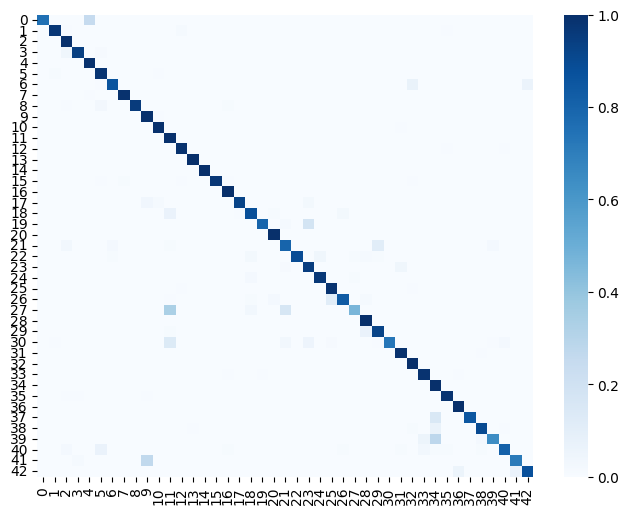

In [25]:
evaluator.plot_confusion_matrix(
    confusion_matrix,
    range(num_class),
    "Blues",
    annot=False,
    figsize=(8, 6),
)

In [26]:
model_path = artifact_path / f"mobilenetV4.{model.key}.pth"

In [27]:
torch.save(model.state_dict(), model_path)

In [28]:
get_file_size(model_path)

'32.81MiB'

In [29]:
model.load_state_dict(torch.load(model_path.as_posix()))

<All keys matched successfully>